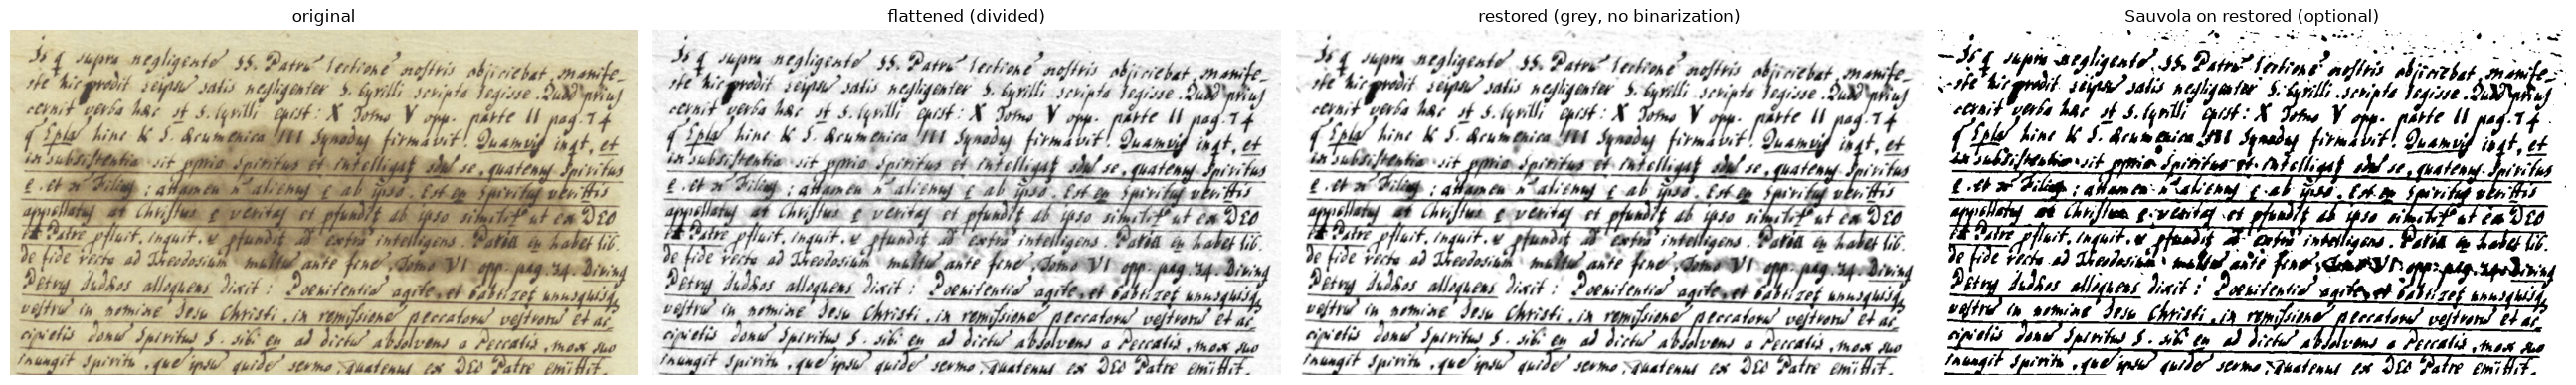

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


# ----------------------------------------------------------------------
# 1. Background estimation
# ----------------------------------------------------------------------
def estimate_background(gray, close_size=45, median_size=31):
    """
    Estimate the paper + stain + illumination background.
    Morphological closing removes dark text (keeps slow variations),
    then a median blur smooths the estimate.
    """
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (close_size, close_size))
    bg = cv2.morphologyEx(gray, cv2.MORPH_CLOSE, k)
    bg = cv2.medianBlur(bg, median_size)
    return bg


# ----------------------------------------------------------------------
# 2. Illumination + stain flattening
# ----------------------------------------------------------------------
def flatten_illumination(gray, bg):
    """
    Divide out the background. Result is roughly [0,255] where
    paper ~ 255 and ink ~ low, regardless of illumination or stain.
    Division (not subtraction) is key: stains and lighting are
    multiplicative, so division removes them cleanly.
    """
    flat = cv2.divide(gray, bg, scale=255)
    return flat.astype(np.uint8)


def suppress_residual_stain(flat, sigma=40, strength=0.7):
    """
    A stain is still a low-frequency darkening after division.
    Estimate that residual with a big Gaussian and pull it back up.
    strength=0 -> no change; strength=1 -> fully flatten residual.
    """
    residual = cv2.GaussianBlur(flat, (0, 0), sigmaX=sigma)
    paper = np.percentile(flat, 95)
    corrected = flat.astype(np.float32) + strength * (paper - residual)
    return np.clip(corrected, 0, 255).astype(np.uint8)


# ----------------------------------------------------------------------
# 3. Grey-level contrast enhancement (no thresholding)
# ----------------------------------------------------------------------
def enhance_ink(flat, gamma=1.4, clip_limit=2.0):
    """
    Contrast enhancement that keeps greys:
    - CLAHE for local contrast (faint strokes)
    - gamma to darken ink without clipping to pure black
    """
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=(8, 8))
    c = clahe.apply(flat)
    f = c.astype(np.float32) / 255.0
    f = np.power(f, gamma)
    return (f * 255).astype(np.uint8)


# ----------------------------------------------------------------------
# 4. Full grey-level restoration pipeline (no binarization)
# ----------------------------------------------------------------------
def restore_grayscale(image_path,
                      close_size=45,
                      median_size=31,
                      stain_sigma=40,
                      stain_strength=0.7,
                      gamma=1.4,
                      clip_limit=2.0,
                      denoise=True):
    """
    Full greyscale (non-binarizing) manuscript restoration.
    Returns a dict of intermediate stages for inspection.
    """
    bgr = cv2.imread(image_path)
    if bgr is None:
        raise FileNotFoundError(image_path)

    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)

    # 1. Background estimate (paper + illumination + stain)
    bg = estimate_background(gray, close_size, median_size)

    # 2. Divide out background -> flatten illumination + most stain
    flat = flatten_illumination(gray, bg)

    # 3. Suppress the stain that survived division
    cleaned = suppress_residual_stain(flat, sigma=stain_sigma,
                                      strength=stain_strength)

    # 4. Edge-preserving denoise (keeps faint strokes)
    if denoise:
        cleaned = cv2.bilateralFilter(cleaned, d=5,
                                      sigmaColor=25, sigmaSpace=25)

    # 5. Enhance ink contrast without binarizing
    enhanced = enhance_ink(cleaned, gamma=gamma, clip_limit=clip_limit)

    return {
        'original':   bgr,
        'gray':       gray,
        'background': bg,
        'flattened':  flat,
        'cleaned':    cleaned,
        'enhanced':   enhanced,
    }


# ----------------------------------------------------------------------
# 5. Optional: binarize ONLY after restoration (if needed for OCR)
# ----------------------------------------------------------------------
def sauvola(gray, window=35, k=0.10, R=128.0):
    """
    Sauvola local adaptive thresholding via box filters. O(N).
    Use this on the RESTORED image, not the raw scan.
    """
    img = gray.astype(np.float32)
    mean = cv2.boxFilter(img, -1, (window, window), normalize=True)
    mean_sq = cv2.boxFilter(img * img, -1, (window, window), normalize=True)
    var = np.clip(mean_sq - mean * mean, 0, None)
    std = np.sqrt(var)
    T = mean * (1.0 + k * ((std / R) - 1.0))
    return np.where(img > T, 255, 0).astype(np.uint8)


# ----------------------------------------------------------------------
# 6. Minimal "just make it readable" variant
# ----------------------------------------------------------------------
def clean_for_reading_v2(gray, close_size=45, gamma=1.4, stain_strength=0.6):
    """
    Compact version: one morphological background pass + one residual
    stain pass + gamma. No binarization anywhere.
    """
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (close_size, close_size))
    bg = cv2.medianBlur(cv2.morphologyEx(gray, cv2.MORPH_CLOSE, k), 31)
    flat = cv2.divide(gray, bg, scale=255).astype(np.float32)

    # second, gentler stain pass
    residual = cv2.GaussianBlur(flat, (0, 0), sigmaX=40)
    paper = np.percentile(flat, 95)
    flat = flat + stain_strength * (paper - residual)

    flat = np.clip(flat, 0, 255) / 255.0
    lo, hi = np.percentile(flat, 1), np.percentile(flat, 60)
    flat = np.clip((flat - lo) / (hi - lo), 0, 1) ** gamma
    return (flat * 255).astype(np.uint8)


# ----------------------------------------------------------------------
# 7. Run it
# ----------------------------------------------------------------------
if __name__ == "__main__":
    path = 'StainImages/Zoernikav folio212.jpg'

    # ---- Full pipeline ----
    res = restore_grayscale(
        path,
        close_size=45,
        median_size=31,
        stain_sigma=40,
        stain_strength=0.7,
        gamma=1.4,
        clip_limit=2.0,
        denoise=True,
    )

    cv2.imwrite('restored_gray.png',  res['enhanced'])
    cv2.imwrite('stage_gray.png',     res['gray'])
    cv2.imwrite('stage_bg.png',       res['background'])
    cv2.imwrite('stage_flat.png',     res['flattened'])
    cv2.imwrite('stage_cleaned.png',  res['cleaned'])

    # ---- Optional: binarize the RESTORED image (not the raw) ----
    binary = sauvola(res['enhanced'], window=25, k=0.05)
    cv2.imwrite('restored_binary.png', binary)

    # ---- Minimal variant ----
    readable = clean_for_reading_v2(res['gray'])
    cv2.imwrite('readable.png', readable)

    # ---- Visual comparison ----
    fig, axes = plt.subplots(1, 4, figsize=(26, 8))
    panels = [
        (cv2.cvtColor(res['original'], cv2.COLOR_BGR2RGB), 'original'),
        (res['flattened'],  'flattened (divided)'),
        (res['enhanced'],   'restored (grey, no binarization)'),
        (binary,            'Sauvola on restored (optional)'),
    ]
    for ax, (img, title) in zip(axes, panels):
        ax.imshow(img, cmap='gray')
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

    # ---- Interactive windows ----
    cv2.imshow('Restored (grey)', res['enhanced'])
    cv2.imshow('Readable (minimal)', readable)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

In [5]:
cv2.imshow('sauvola', binary)
cv2.imshow('restored_gray', res['enhanced'])

cv2.waitKey(0)
cv2.destroyAllWindows()

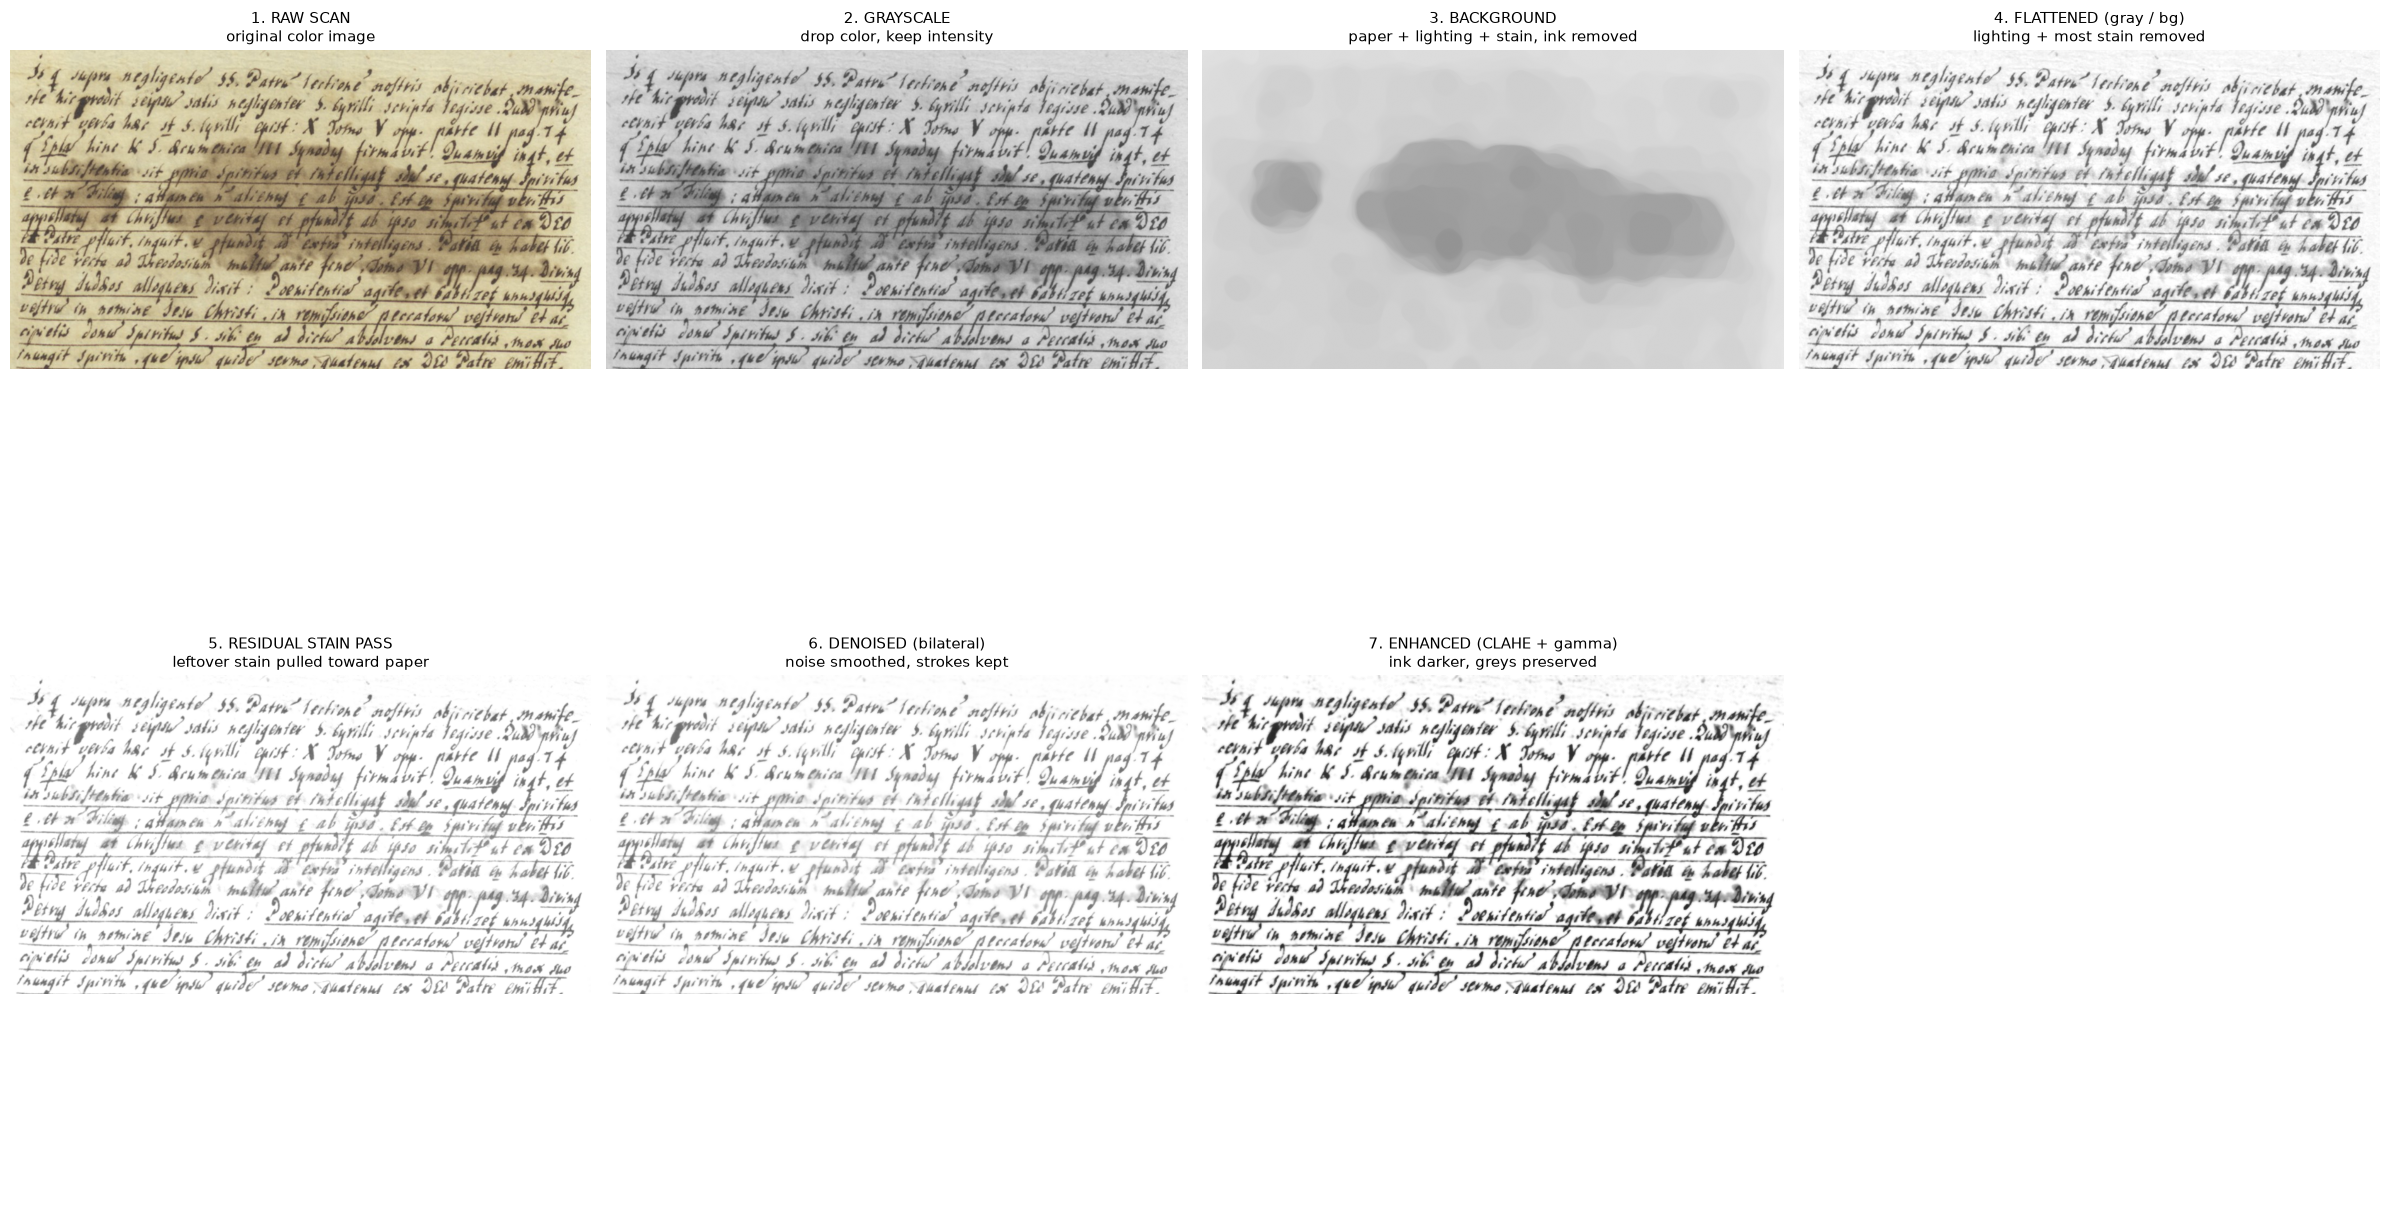

In [1]:
# ======================================================================
# VISUALIZE EVERY STAGE OF THE RESTORATION FLOW
# ======================================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------------------------------------------------
# Re-declare each stage as a tiny function so we can capture its output
# ----------------------------------------------------------------------
def stage_grayscale(bgr):
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)

def stage_background(gray, close_size=45, median_size=31):
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (close_size, close_size))
    bg = cv2.morphologyEx(gray, cv2.MORPH_CLOSE, k)
    bg = cv2.medianBlur(bg, median_size)
    return bg

def stage_flatten(gray, bg):
    return cv2.divide(gray, bg, scale=255).astype(np.uint8)

def stage_residual(flat, sigma=40, strength=0.7):
    residual = cv2.GaussianBlur(flat, (0, 0), sigmaX=sigma)
    paper = np.percentile(flat, 95)
    corrected = flat.astype(np.float32) + strength * (paper - residual)
    return np.clip(corrected, 0, 255).astype(np.uint8)

def stage_denoise(cleaned, d=5, sigmaColor=25, sigmaSpace=25):
    return cv2.bilateralFilter(cleaned, d, sigmaColor, sigmaSpace)

def stage_enhance(denoised, gamma=1.4, clip_limit=2.0):
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=(8, 8))
    c = clahe.apply(denoised)
    f = c.astype(np.float32) / 255.0
    f = np.power(f, gamma)
    return (f * 255).astype(np.uint8)

# ----------------------------------------------------------------------
# Run the full flow and collect every stage
# ----------------------------------------------------------------------
def show_flow(image_path,
              close_size=45,
              median_size=31,
              stain_sigma=40,
              stain_strength=0.7,
              bilateral_d=5,
              bilateral_sigmaColor=25,
              bilateral_sigmaSpace=25,
              gamma=1.4,
              clip_limit=2.0,
              figsize=(24, 14)):
    """
    Run the restoration pipeline on image_path and display every stage
    in a labelled grid.
    """
    bgr = cv2.imread(image_path)
    if bgr is None:
        raise FileNotFoundError(image_path)

    # ---- run each stage, capturing its output ----
    gray       = stage_grayscale(bgr)
    bg         = stage_background(gray, close_size, median_size)
    flat       = stage_flatten(gray, bg)
    cleaned    = stage_residual(flat, stain_sigma, stain_strength)
    denoised   = stage_denoise(cleaned, bilateral_d,
                               bilateral_sigmaColor, bilateral_sigmaSpace)
    enhanced   = stage_enhance(denoised, gamma, clip_limit)

    # ---- pack stages with labels and descriptions ----
    stages = [
        (cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB), '1. RAW SCAN',
         'original color image'),
        (gray, '2. GRAYSCALE',
         'drop color, keep intensity'),
        (bg, '3. BACKGROUND',
         'paper + lighting + stain, ink removed'),
        (flat, '4. FLATTENED (gray / bg)',
         'lighting + most stain removed'),
        (cleaned, '5. RESIDUAL STAIN PASS',
         'leftover stain pulled toward paper'),
        (denoised, '6. DENOISED (bilateral)',
         'noise smoothed, strokes kept'),
        (enhanced, '7. ENHANCED (CLAHE + gamma)',
         'ink darker, greys preserved'),
    ]

    # ---- plot ----
    n = len(stages)
    cols = 4
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    axes = axes.flatten()

    for ax, (img, title, subtitle) in zip(axes, stages):
        if img.ndim == 3:
            ax.imshow(img)
        else:
            ax.imshow(img, cmap='gray', vmin=0, vmax=255)
        ax.set_title(f"{title}\n{subtitle}", fontsize=11)
        ax.axis('off')

    # hide any unused panels
    for ax in axes[len(stages):]:
        ax.axis('off')

    plt.tight_layout()
    plt.show()

    # ---- also return the stages so you can save/inspect them ----
    return {
        'raw':       bgr,
        'gray':      gray,
        'bg':        bg,
        'flat':      flat,
        'cleaned':   cleaned,
        'denoised':  denoised,
        'enhanced':  enhanced,
    }

# ----------------------------------------------------------------------
# Run it
# ----------------------------------------------------------------------
stages = show_flow('StainImages/Zoernikav folio212.jpg')

# Optional: save every stage to disk
for name, img in stages.items():
    out = img if img.ndim == 3 else cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    cv2.imwrite(f'stage_{name}.png', out)